# GiftLane — PCA vs. Truncated SVD: Analysis Notebook

**Individual project: one student carries out both Data Engineer and ML Engineer roles.**  
Source: Chen, D. (2012), *Online Retail II*, UCI Machine Learning Repository.

This notebook displays and validates the results from the project scripts. **Run these scripts from the repository root before using this notebook:**

```bash
python data_profile.py
python build_matrix.py
python matrix_report.py
python train_svd.py
python recommend.py
python evaluate.py
python compare_models.py
python compare_pca_svd.py
python customer_segments.py
python analyze_segments.py
python sensitivity_analysis.py
```

Data are held out **before** dimensionality reduction. Outputs do not display individual customer identifiers.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display, Image
import pickle
DATA = Path("data/processed")
REPORTS = Path("reports")
required = [DATA / "customer_product_matrix.npz", DATA / "test.pkl", REPORTS / "svd_results.csv", REPORTS / "evaluation_results.csv", REPORTS / "pca_vs_svd.csv", REPORTS / "segment_profiles.csv", REPORTS / "sensitivity_results.csv"]
missing = [str(x) for x in required if not x.exists()]
if missing:
    raise FileNotFoundError("Run project scripts from repo root first; missing: " + ", ".join(missing))
print("All required analysis inputs found.")

All required analysis inputs found.


## DE1–DE5 — Data profile, split, and sparse matrix

- Raw data: 1,067,371 transaction lines from two sheets; 802,920 after cleaning.
- Time-based split: 684,312 training rows; final two months held out.
- A purchase is counted as eligible test data only when the customer did not purchase that product during training.
- Matrix cell: `log(1 + total customer–product quantity)`. Products with fewer than 10 unique buyers were excluded.

**Justification:** cancellations, administrative codes, non-positive values and missing customer IDs do not represent usable positive customer purchases. A sparse CSR matrix stores only nonzero purchases efficiently.

In [10]:
A = sp.load_npz(DATA / "customer_product_matrix.npz").tocsr()
print("Matrix shape:", A.shape)
print("Nonzero pairs:", A.nnz)
print("Sparsity: {:.2%}".format(1 - A.nnz / (A.shape[0] * A.shape[1])))
assert A.shape == (5475, 3689)
assert A.nnz == 413983
matrix_report = pd.read_csv(REPORTS / "matrix_report.csv")
display(matrix_report)

Matrix shape: (5475, 3689)
Nonzero pairs: 413983
Sparsity: 97.95%


,Metric,Value
0,Customers,5475.00
1,Products,3689.00
2,Total Entries,20197275.00
3,Non-zero Entries,413983.00
4,Sparsity (%),97.95
5,Density (%),2.05
6,Dense Memory (MiB),154.09
7,Sparse Memory (MiB),4.76
8,Memory Reduction (%),96.91
9,Compression Ratio,32.38


### Held-out integrity check

This check verifies that evaluation pairs known to the training mappings are not already positive entries in the training matrix. It is an additional check beyond successful script execution.

In [11]:
with open(DATA / "customer_map.pkl", "rb") as f:
    customer_map = pickle.load(f)
with open(DATA / "product_map.pkl", "rb") as f:
    product_map = pickle.load(f)
test = pd.read_pickle(DATA / "test.pkl").copy()
test["StockCode"] = test["StockCode"].astype(str).str.strip()
test["r"] = test["Customer ID"].map(customer_map)
test["c"] = test["StockCode"].map(product_map)
known = test.dropna(subset=["r", "c"]).drop_duplicates(["r", "c"])
r = known["r"].to_numpy(dtype=int)
c = known["c"].to_numpy(dtype=int)
number_of_overlaps = int(np.count_nonzero(np.asarray(A[r, c]).ravel()))
print("Evaluable unique pairs:", len(known))
print("Held-out pairs already bought in training:", number_of_overlaps)
assert number_of_overlaps == 0, "Unexpected training/test overlap"

Evaluable unique pairs: 44729
Held-out pairs already bought in training: 0


## ML1–ML2 — Truncated SVD and reconstruction

Truncated SVD is chosen because it accepts CSR input without subtracting a mean from every product column. Test `k ∈ {10, 20, 50, 100, 200}` on the training matrix. Reconstruction error is a matrix approximation metric, not a recommendation error rate.

,k,customers,original_features,reduced_features,explained_variance_ratio,relative_reconstruction_error
0,10,5475,3689,10,0.198252,0.876086
1,20,5475,3689,20,0.252471,0.845842
2,50,5475,3689,50,0.348831,0.789411
3,100,5475,3689,100,0.447240,0.727291
4,200,5475,3689,200,0.573612,0.638755


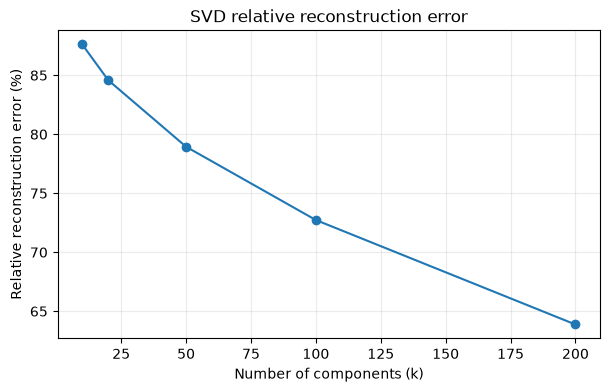

In [12]:
svd = pd.read_csv(REPORTS / "svd_results.csv")
display(svd)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(svd["k"], 100 * svd["relative_reconstruction_error"], marker="o")
ax.set(title="SVD relative reconstruction error", xlabel="Number of components (k)", ylabel="Relative reconstruction error (%)")
ax.grid(alpha=.25)
plt.show()

## ML3–ML4 — Recommendation quality

For each customer, the model recommends 10 products not purchased in training. Holdout Hit Rate@10 counts a customer as successful when **at least one** of the ten recommendations appears in their future held-out purchases. Precision and recall are averaged over eligible customers.

,model,eligible_customers,precision_at_10,recall_at_10,hit_rate_at_10
0,Popularity Baseline,1913,0.022582,0.011532,0.174072
1,SVD k=10,1913,0.046994,0.028867,0.308939
2,SVD k=20,1913,0.055044,0.037101,0.350235
3,SVD k=50,1913,0.061265,0.043225,0.373236
4,SVD k=100,1913,0.059958,0.043805,0.380554


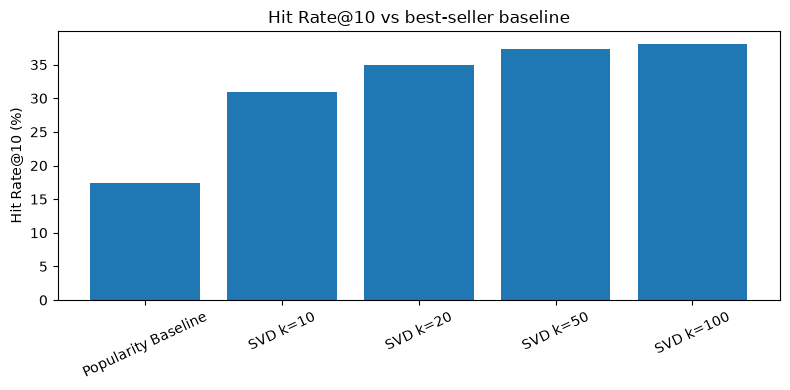

In [13]:
evaluation = pd.read_csv(REPORTS / "evaluation_results.csv")
display(evaluation)
assert evaluation["eligible_customers"].nunique() == 1
assert evaluation["eligible_customers"].iloc[0] == 1913
assert evaluation["hit_rate_at_10"].between(0,1).all()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(evaluation["model"], 100 * evaluation["hit_rate_at_10"])
ax.set(title="Hit Rate@10 vs best-seller baseline", ylabel="Hit Rate@10 (%)")
ax.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()

## ML5 — PCA vs. Truncated SVD at k=50

Compare the same training matrix at the same number of components. Peak process RSS includes interpreter and library memory and **is not** isolated fit memory. Differences in fitting time or memory across runs are normal.

In [14]:
comparison = pd.read_csv(REPORTS / "pca_vs_svd.csv")
display(comparison)
assert set(comparison["method"].str.upper()) == {"PCA", "SVD"}
assert set(comparison["k"]) == {50}

,method,k,fit_seconds,peak_process_rss_mb,stored_factors_mb,explained_variance_ratio,hit_rate_at_10,eligible_customers,component_1_top_products,baseline_hit_rate_at_10
0,PCA,50,0.102109,207.921875,3.523933,0.349302,0.372713,1913,"21212, 85099B, 20725, 85123A, 84991",0.174072
1,SVD,50,0.105722,234.640625,3.495789,0.348831,0.373236,1913,"21212, 85123A, 85099B, 20725, 84991",0.174072


**Component 1:** The highest absolute-loading product codes are similar for PCA and SVD (`21212`, `85099B`, `20725`, `85123A`, `84991`). Without checking signs and product descriptions, do not assign an overconfident semantic label to the component.

**Model selection:** Log SVD k=50 had the highest Precision@10 among the tested log models, but k=100 had higher Hit Rate@10. This matters because the primary stakeholder metric is Hit Rate@10.

## ML6 — Customer map and named segments

For the assignment's required cluster range 3–6, the k=3 solution had the best sampled silhouette score. Cluster labels are exploratory; a group of only 12 customers may not be stable or useful for marketing.

,n_clusters,silhouette_score
0,3,0.525269
1,4,0.368198
2,5,0.328826
3,6,0.318401


,segment,customer_count,customer_percentage,top_products,top_countries
0,Segment 0,4734,86.465753,WHITE HANGING HEART T-LIGHT HOLDER | REGENCY C...,United Kingdom | Germany | France
1,Segment 1,729,13.315068,PACK OF 72 RETROSPOT CAKE CASES | JUMBO BAG RE...,United Kingdom | Germany | France
2,Segment 2,12,0.219178,RED SPOTTY BOWL | LUNCH BAG RED RETROSPOT | LU...,United Kingdom | EIRE | Australia


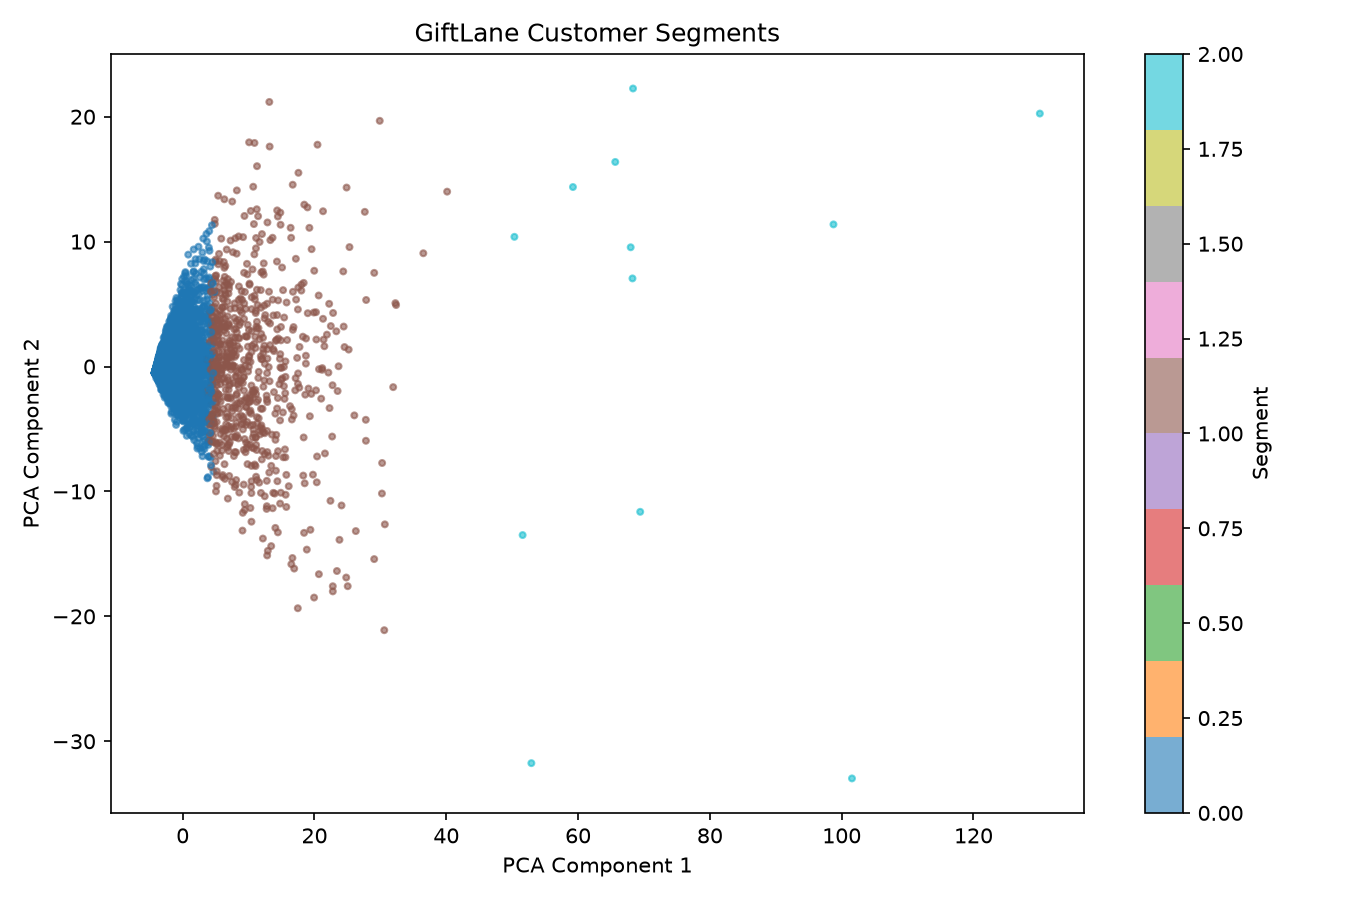

In [15]:
silhouette = pd.read_csv(REPORTS / "silhouette_results_final.csv")
profiles = pd.read_csv(REPORTS / "segment_profiles.csv")
display(silhouette)
display(profiles)
image_path = REPORTS / "customer_segments_final.png"
if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Customer map image missing. Generate it with python analyze_segments.py")

## ML7 — Purchase value sensitivity

At k=50, Count, Binary and Log were compared with the same training/test boundary. Binary had the best observed Hit Rate@10, although further experiments across k are needed before deployment.

,purchase_value,k,eligible_customers,matrix_shape,hit_rate_at_10,precision_at_10,recall_at_10,explained_variance_ratio
0,Count,50,1913,"(5475, 3689)",0.211187,0.026817,0.016892,0.963680
1,Binary,50,1913,"(5475, 3689)",0.401464,0.067486,0.046563,0.273632
2,Log,50,1913,"(5475, 3689)",0.373236,0.061265,0.043225,0.348831


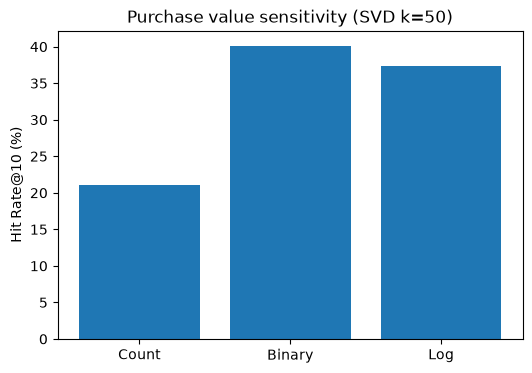

In [16]:
sensitivity = pd.read_csv(REPORTS / "sensitivity_results.csv")
display(sensitivity)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(sensitivity["purchase_value"], 100 * sensitivity["hit_rate_at_10"])
ax.set(title="Purchase value sensitivity (SVD k=50)", ylabel="Hit Rate@10 (%)")
plt.show()

## Business conclusion and limitations

- Compared with a best-seller baseline (17.41%), Log SVD k=50 obtained 37.32% Hit Rate@10; Binary SVD k=50 obtained 40.15%.
- CSR storage reduced memory from 154.09 MiB dense to 4.76 MiB; this is **sparse storage** rather than SVD storage reduction.
- The measured recommendation job is not a full end-to-end nightly training pipeline.
- Cold-start products and new customers are excluded from some evaluations; performance does not represent all future customers or purchases.
- PCA and SVD performance is nearly tied at k=50; SVD was kept for sparse-input compatibility.
- Marketing labels for clusters are preliminary, especially for the smallest group.

No customer IDs are printed or displayed in this notebook.